# Практична робота 4.5
## Використання методів штучного інтелекту для аналізу даних (класифікація з набору даних Kaggle)

**Набір даних:** [Titanic — Machine Learning from Disaster](https://www.kaggle.com/c/titanic) (файл `train.csv`, 891 пасажир, тут збережений як `titanic.csv`).

**Задача:** за характеристиками пасажира передбачити, чи він вижив (`Survived`: 1 — вижив, 0 — загинув). Це задача **бінарної класифікації**.

**План роботи**
1. Завантаження даних та первинний огляд.
2. Попередня обробка: пропущені значення, нові ознаки, кодування категоріальних змінних, баланс класів.
3. Розподіл на тренувальний і тестовий набори 80:20.
4. Моделі: логістична регресія та KNN.
5. Оцінка: accuracy, precision, recall, F1, матриця плутанини, ROC-крива.
6. Додатково: Random Forest та SVM, порівняння всіх моделей.
7. Звіт і висновки.

## 1. Завантаження даних

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score,
                             classification_report)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

# Локальний файл (завантажений з Kaggle). Якщо його немає — беремо публічну копію того ж train.csv.
try:
    data = pd.read_csv("titanic.csv")
except FileNotFoundError:
    data = pd.read_csv("https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv")

print("Розмір набору:", data.shape)
data.head()

Розмір набору: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


**Опис ознак:** `Pclass` — клас квитка (1–3), `Sex` — стать, `Age` — вік, `SibSp` — кількість братів/сестер/подружжя на борту, `Parch` — батьків/дітей на борту, `Fare` — вартість квитка, `Cabin` — номер каюти, `Embarked` — порт посадки (C, Q, S). `PassengerId`, `Ticket` — ідентифікатори, корисної інформації майже не несуть.

## 2. Попередня обробка даних
### 2.1. Пропущені значення

In [3]:
missing = data.isnull().sum()
missing_pct = (missing / len(data) * 100).round(1)
pd.DataFrame({"пропусків": missing, "%": missing_pct})[missing > 0]

,пропусків,%
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


Пропуски є у трьох стовпцях:
- `Age` (~20%) — заповнимо **медіаною** (вік має асиметричний розподіл, медіана стійкіша до викидів, ніж середнє). Щоб урахувати, що вік сильно залежить від звертання (Mr/Mrs/Miss/Master), беремо медіану **в межах групи за титулом**.
- `Embarked` (2 записи) — заповнимо **модою** (найчастішим портом).
- `Cabin` (~77%) — заповнити неможливо, тому замінимо стовпець бінарною ознакою `HasCabin` (чи відома каюта).

Важливо: медіану та моду обчислюємо **лише на тренувальній частині**, щоб інформація з тестових даних не «просочилась» у навчання (data leakage). Тому спочатку створимо ознаки, а заповнення пропусків зробимо після розподілу.

### 2.2. Нові ознаки (feature engineering)

In [4]:
df = data.copy()

# Титул із імені: "Braund, Mr. Owen Harris" -> "Mr"
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
rare = df["Title"].value_counts()[lambda s: s < 10].index
df["Title"] = df["Title"].replace(dict.fromkeys(rare, "Rare"))

df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
df["HasCabin"] = df["Cabin"].notna().astype(int)

df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])
print(df["Title"].value_counts())
df.head()

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,FamilySize,IsAlone,HasCabin
0,0,3,male,22.0,1,0,7.2500,S,Mr,2,0,0
1,1,1,female,38.0,1,0,71.2833,C,Mrs,2,0,1
2,1,3,female,26.0,0,0,7.9250,S,Miss,1,1,0
3,1,1,female,35.0,1,0,53.1000,S,Mrs,2,0,1
4,0,3,male,35.0,0,0,8.0500,S,Mr,1,1,0


### 2.3. Баланс класів у цільовій змінній

Survived
0    549
1    342
Name: count, dtype: int64
Частка тих, хто вижив: 38.4%


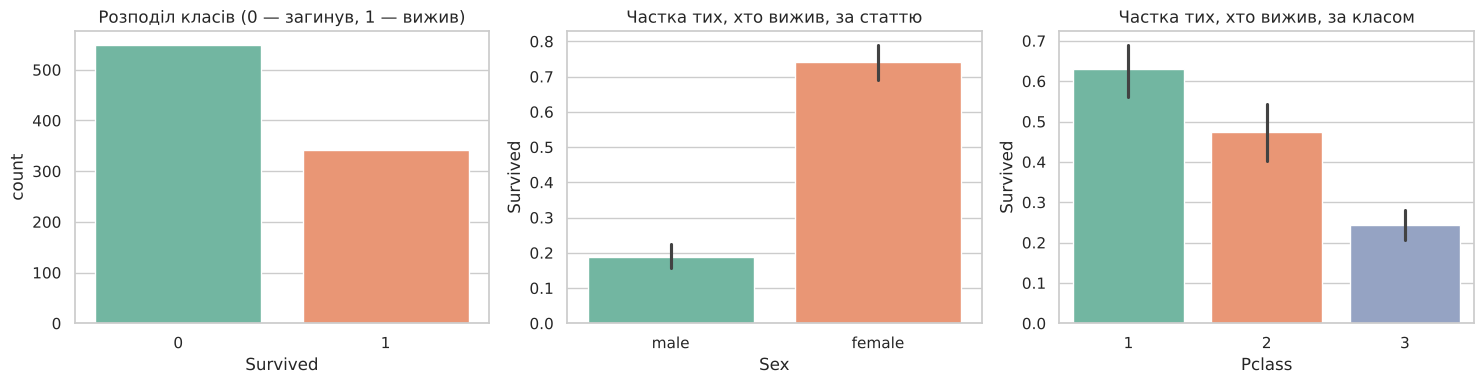

In [5]:
counts = df["Survived"].value_counts().sort_index()
print(counts)
print("Частка тих, хто вижив: {:.1%}".format(df["Survived"].mean()))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x="Survived", data=df, ax=axes[0], palette="Set2")
axes[0].set_title("Розподіл класів (0 — загинув, 1 — вижив)")
sns.barplot(x="Sex", y="Survived", data=df, ax=axes[1], palette="Set2")
axes[1].set_title("Частка тих, хто вижив, за статтю")
sns.barplot(x="Pclass", y="Survived", data=df, ax=axes[2], palette="Set2")
axes[2].set_title("Частка тих, хто вижив, за класом")
plt.tight_layout()
plt.show()

Класи **помірно незбалансовані**: ~62% загинули, ~38% вижили. Це не критично, але:
- accuracy слід доповнювати precision/recall/F1;
- розподіл на train/test робимо **стратифікованим** (`stratify=y`), щоб пропорція класів була однаковою в обох частинах.

Вже з графіків видно найсильніші чинники: жінки та пасажири 1-го класу мали значно більші шанси вижити.

## 3. Розподіл даних (80:20)

In [6]:
X = df.drop(columns="Survived")
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
X_train, X_test = X_train.copy(), X_test.copy()
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Частка класу 1 — train: {:.3f}, test: {:.3f}".format(y_train.mean(), y_test.mean()))

Train: (712, 11)  Test: (179, 11)
Частка класу 1 — train: 0.383, test: 0.385


### 3.1. Заповнення пропусків (статистики — лише з train) та one-hot кодування

In [7]:
age_by_title = X_train.groupby("Title")["Age"].median()
age_overall = X_train["Age"].median()
embarked_mode = X_train["Embarked"].mode()[0]
print("Медіанний вік за титулом (train):\n", age_by_title.round(1))
print("Мода Embarked (train):", embarked_mode)

def fill_missing(part):
    part["Age"] = part["Age"].fillna(part["Title"].map(age_by_title)).fillna(age_overall)
    part["Embarked"] = part["Embarked"].fillna(embarked_mode)
    return part

X_train = fill_missing(X_train)
X_test = fill_missing(X_test)

# One-hot encoding категоріальних змінних
cat_cols = ["Sex", "Embarked", "Title"]
X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)  # однаковий набір стовпців

print("Пропусків після обробки — train:", X_train.isnull().sum().sum(), ", test:", X_test.isnull().sum().sum())
print("Ознаки моделі:", list(X_train.columns))
X_train.head()

Медіанний вік за титулом (train):
 Title
Master     3.0
Miss      22.0
Mr        30.0
Mrs       35.0
Rare      49.0
Name: Age, dtype: float64
Мода Embarked (train): S
Пропусків після обробки — train: 0 , test: 0
Ознаки моделі: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'HasCabin', 'Sex_male', 'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']


,Pclass,Age,SibSp,Parch,Fare,FamilySize,IsAlone,HasCabin,Sex_male,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
692,3,30.0,0,0,56.4958,1,1,0,1,0,1,0,1,0,0
481,2,30.0,0,0,0.0000,1,1,0,1,0,1,0,1,0,0
527,1,30.0,0,0,221.7792,1,1,1,1,0,1,0,1,0,0
855,3,18.0,0,1,9.3500,2,0,0,0,0,1,0,0,1,0
801,2,31.0,1,1,26.2500,3,0,0,0,0,1,0,0,1,0


Для логістичної регресії, KNN та SVM важливий масштаб ознак (наприклад, `Fare` до 512, а бінарні ознаки 0/1), тому для них використовуємо `StandardScaler` всередині `Pipeline` — масштабувальник також навчається лише на train.

## 4. Побудова моделей класифікації: логістична регресія та KNN

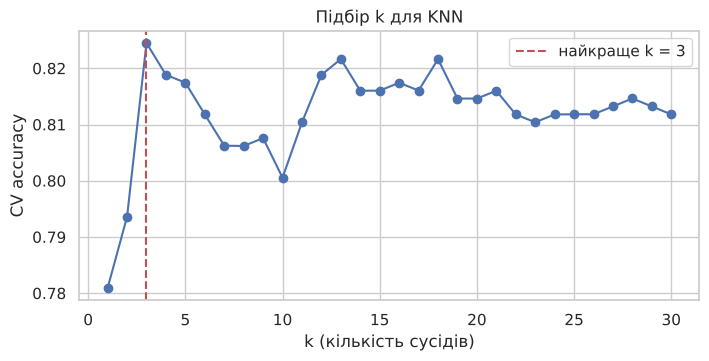


=== Логістична регресія ===
              precision    recall  f1-score   support

     Загинув      0.866     0.882     0.874       110
       Вижив      0.806     0.783     0.794        69

    accuracy                          0.844       179
   macro avg      0.836     0.832     0.834       179
weighted avg      0.843     0.844     0.843       179


=== KNN (k=3) ===
              precision    recall  f1-score   support

     Загинув      0.849     0.818     0.833       110
       Вижив      0.726     0.768     0.746        69

    accuracy                          0.799       179
   macro avg      0.788     0.793     0.790       179
weighted avg      0.802     0.799     0.800       179



In [8]:
def evaluate(name, model):
    """Навчає модель, рахує метрики на тесті та 5-fold CV-accuracy на train."""
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    cv = cross_val_score(model, X_train, y_train,
                         cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))
    return {
        "Модель": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_prob),
        "CV accuracy (train)": cv.mean(),
    }, y_pred, y_prob

models = {}
results = {}

models["Логістична регресія"] = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

# Підбір k для KNN за крос-валідацією на train (тест не використовуємо для підбору!)
ks = range(1, 31)
cv_scores = [cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(k)), X_train, y_train,
                             cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)).mean() for k in ks]
best_k = ks[int(np.argmax(cv_scores))]
plt.figure(figsize=(8, 3.5))
plt.plot(ks, cv_scores, marker="o")
plt.axvline(best_k, color="r", ls="--", label=f"найкраще k = {best_k}")
plt.xlabel("k (кількість сусідів)"); plt.ylabel("CV accuracy"); plt.title("Підбір k для KNN")
plt.legend(); plt.show()

models[f"KNN (k={best_k})"] = make_pipeline(StandardScaler(), KNeighborsClassifier(best_k))

for name in list(models):
    results[name] = evaluate(name, models[name])
    print(f"\n=== {name} ===")
    print(classification_report(y_test, results[name][1], target_names=["Загинув", "Вижив"], digits=3))

## 5. Оцінка моделей
### 5.1. Метрики

In [9]:
pd.DataFrame([r[0] for r in results.values()]).set_index("Модель").round(3)

,Accuracy,Precision,Recall,F1,ROC AUC,CV accuracy (train)
Модель,,,,,,
Логістична регресія,0.844,0.806,0.783,0.794,0.874,0.829
KNN (k=3),0.799,0.726,0.768,0.746,0.828,0.824


**Що означають метрики (клас 1 = «вижив»):**
- **Accuracy** — частка всіх правильних прогнозів.
- **Precision** — з тих, кого модель назвала «вижив», яка частка справді вижила.
- **Recall** — яку частку реально вцілілих модель знайшла.
- **F1** — гармонійне середнє precision і recall.
- **ROC AUC** — якість ранжування за ймовірністю незалежно від порогу (0.5 — випадкове вгадування, 1 — ідеал).

### 5.2. Матриця плутанини

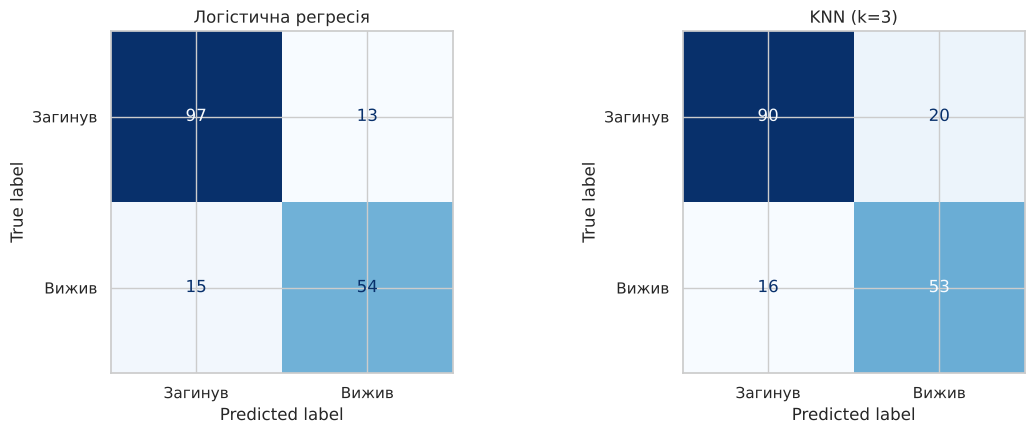

In [10]:
fig, axes = plt.subplots(1, len(results), figsize=(6 * len(results), 4.5))
for ax, (name, (_, y_pred, _)) in zip(np.atleast_1d(axes), results.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=["Загинув", "Вижив"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

### 5.3. ROC-крива

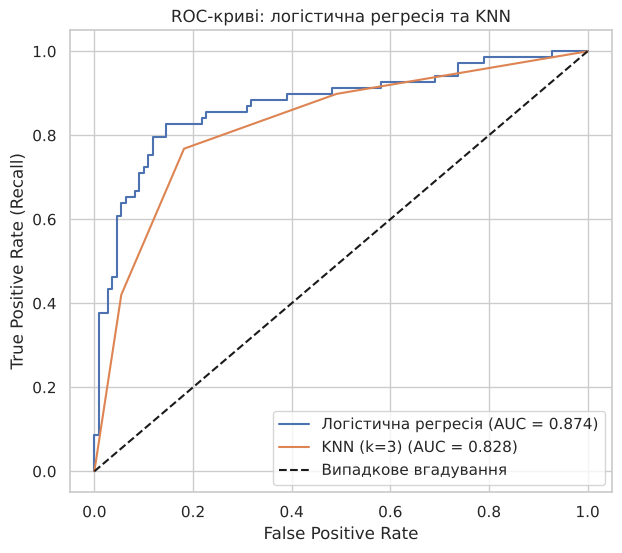

In [11]:
def plot_roc(res, title):
    plt.figure(figsize=(7, 6))
    for name, (m, _, y_prob) in res.items():
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        plt.plot(fpr, tpr, label=f"{name} (AUC = {m['ROC AUC']:.3f})")
    plt.plot([0, 1], [0, 1], "k--", label="Випадкове вгадування")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate (Recall)")
    plt.title(title); plt.legend(loc="lower right"); plt.show()

plot_roc(results, "ROC-криві: логістична регресія та KNN")

## 6. Додаткове завдання: Random Forest та SVM

In [12]:
models["Random Forest"] = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=2,
                                                 random_state=RANDOM_STATE)
models["SVM (RBF)"] = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, probability=True,
                                                          random_state=RANDOM_STATE))
for name in ["Random Forest", "SVM (RBF)"]:
    results[name] = evaluate(name, models[name])

summary = pd.DataFrame([r[0] for r in results.values()]).set_index("Модель").round(3)
summary.sort_values("F1", ascending=False)

,Accuracy,Precision,Recall,F1,ROC AUC,CV accuracy (train)
Модель,,,,,,
Логістична регресія,0.844,0.806,0.783,0.794,0.874,0.829
SVM (RBF),0.827,0.797,0.739,0.767,0.851,0.836
KNN (k=3),0.799,0.726,0.768,0.746,0.828,0.824
Random Forest,0.821,0.825,0.681,0.746,0.850,0.819


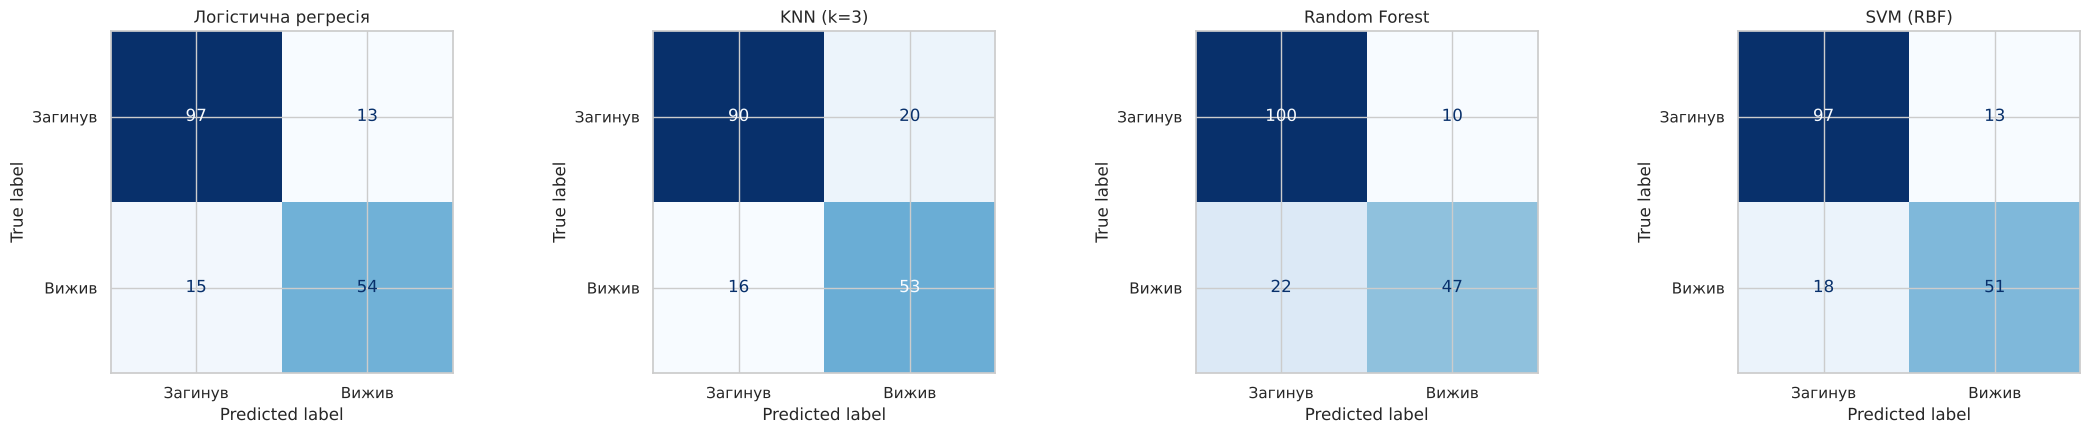

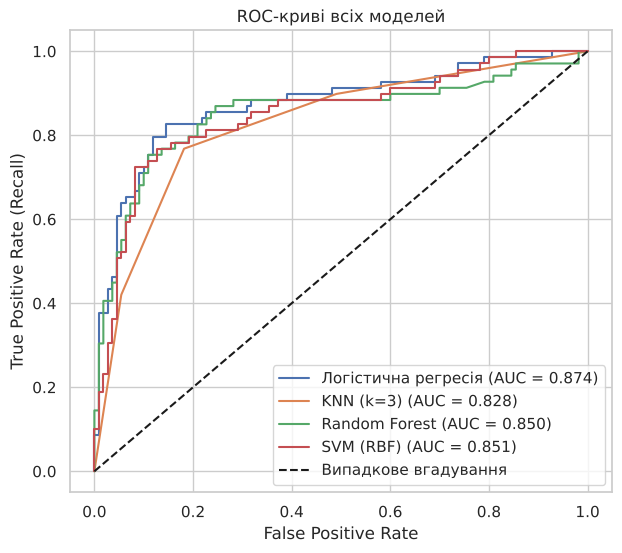

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, (name, (_, y_pred, _)) in zip(axes, results.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=["Загинув", "Вижив"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

plot_roc(results, "ROC-криві всіх моделей")

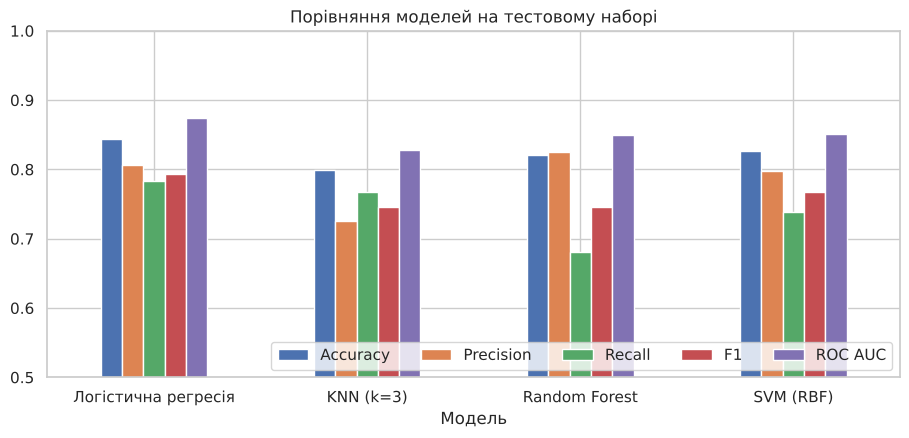

In [14]:
summary[["Accuracy", "Precision", "Recall", "F1", "ROC AUC"]].plot.bar(figsize=(11, 4.5), rot=0)
plt.ylim(0.5, 1); plt.title("Порівняння моделей на тестовому наборі"); plt.legend(loc="lower right", ncol=5)
plt.show()

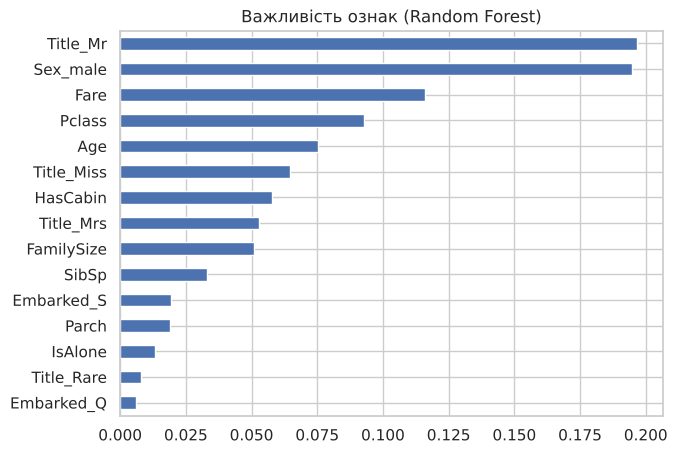

In [15]:
# Важливість ознак за Random Forest — що найбільше впливає на прогноз
imp = pd.Series(models["Random Forest"].feature_importances_, index=X_train.columns).sort_values()
imp.plot.barh(figsize=(7, 5), title="Важливість ознак (Random Forest)")
plt.show()

## 7. Звіт

In [16]:
best = summary["F1"].idxmax()
print("Найкраща модель за F1:", best)
print(summary.loc[best].to_string())

Найкраща модель за F1: Логістична регресія
Accuracy               0.844
Precision              0.806
Recall                 0.783
F1                     0.794
ROC AUC                0.874
CV accuracy (train)    0.829


### Використаний підхід
- **Дані:** Kaggle Titanic, 891 пасажир, 11 вихідних ознак; цільова змінна `Survived`.
- **Обробка:** пропуски `Age` заповнено медіаною за титулом, `Embarked` — модою, `Cabin` замінено ознакою `HasCabin`; додано ознаки `Title`, `FamilySize`, `IsAlone`; категоріальні ознаки закодовано one-hot. Усі статистики для заповнення та масштабування обчислено лише на тренувальній частині.
- **Розподіл:** 80/20 зі стратифікацією за класом (712 / 179 записів).
- **Моделі:** логістична регресія, KNN (k підібрано 5-кратною крос-валідацією на train), Random Forest, SVM з RBF-ядром.

### Ключові результати

| Модель | Accuracy | Precision | Recall | F1 | ROC AUC | CV acc (train) |
|---|---:|---:|---:|---:|---:|---:|
| Логістична регресія | **0.844** | 0.806 | **0.783** | **0.794** | **0.874** | 0.829 |
| SVM (RBF) | 0.827 | 0.797 | 0.739 | 0.767 | 0.851 | **0.836** |
| KNN (k=3) | 0.799 | 0.726 | 0.768 | 0.746 | 0.828 | 0.824 |
| Random Forest | 0.821 | **0.825** | 0.681 | 0.746 | 0.850 | 0.819 |

- Класи помірно незбалансовані (38% вижили), тому окрім accuracy аналізували precision, recall та F1.
- На тестовому наборі найкращою за всіма основними метриками виявилась **логістична регресія** (accuracy 0.844, F1 0.794, AUC 0.874).
- **Random Forest** має найвищу precision (0.825), але найнижчий recall (0.681): він «обережний» і пропускає частину вцілілих. **KNN** — навпаки, recall вищий за precision.
- Матриці плутанини показують, що основний тип помилок більшості моделей — хибно негативні (вцілілих прогнозують як загиблих).
- Найважливіші ознаки — стать/титул, вартість квитка, клас, вік і розмір сім'ї, що узгоджується з принципом «спершу жінки та діти» і з перевагою пасажирів вищих класів.

### Висновки
1. Проста логістична регресія дала найкращий результат: основні залежності в даних близькі до лінійних (стать, титул, клас), а добре сконструйовані ознаки важать більше за складність моделі.
2. SVM і Random Forest не дали переваги на тесті; за крос-валідацією SVM трохи кращий (0.836 проти 0.829), тож різниця між моделями (1–3 п.п.) порівнянна зі статистичним шумом тестового набору з 179 записів.
3. KNN найчутливіший до масштабу ознак і вибору k (підібрано k=3 за CV), і показав найслабший результат.
4. Можливі покращення: підбір гіперпараметрів через `GridSearchCV`, зміна порогу класифікації для балансу precision/recall, додаткові ознаки (палуба з `Cabin`, групи за квитком), ансамблювання моделей.